<a href="https://colab.research.google.com/github/ramithuh/differentiable-trees/blob/main/feature-testing/Differentiable_UPGMA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import jax.numpy as jnp
import numpy as np
import jax
import jax.nn as nn
import sys
import functools

In [2]:
!pip -q install biopython

In [3]:
if "google.colab" in sys.modules:
    %pip install -q git+https://github.com/ott-jax/ott@main



from ott.tools import soft_sort

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


/usr/local/lib/python3.9/dist-packages/flax/core/frozen_dict.py:169: FutureWarning: jax.tree_util.register_keypaths is deprecated, and will be removed in a future release. Please use `register_pytree_with_keys()` instead.
  jax.tree_util.register_keypaths(


In [4]:
softranks = jax.jit(soft_sort.ranks)

In [5]:
dm = jnp.array([[  0, 32, 48, 51, 50, 48, 98,148],
                [ 32,  0, 26, 34, 29, 33, 84,136],
                [ 48, 26,  0, 42, 44, 44, 92,152],
                [ 51, 34, 42,  0, 44, 38, 86,142],
                [ 50, 29, 44, 44,  0, 24, 89,142],
                [ 48, 33, 44, 38, 24,  0, 90,142],
                [ 98, 84, 92, 86, 89, 90,  0,148],
                [148,136,152,142,142,142,148,  0]])
      
labels = ["Dog","Bear","Raccoon","Weasel","Seal","SeaLion","Cat","Monkey"]

In [8]:
def get_prototypes(indices, dim):
  zeros = np.zeros((indices[0].shape[0], dim))

  for i in range(0,indices[0].shape[0]):
    zeros[i][indices[0][i]] = 1
    zeros[i][indices[1][i]] = 1
    


  return zeros


In [9]:
jnp.set_printoptions(precision=1, suppress=True)

### Defining helper functions

In [10]:
def expand_matrix(mat, sel):

  dim = mat.shape[0]
  e   = get_expansion_matrix(dim, sel)
  

  sol = np.zeros((dim+1,dim+1))
  sol[:,:-1] = sol[:,:-1] + (e.T @ mat)
  sol[:-1,:] = sol[:-1,:] + (mat @ e)

  return sol/2

In [11]:
def get_expansion_matrix(source_dim, sel):
  '''
    Design choices:
      -> assumes that the joining leavess are the first two 

  '''
  a = jnp.eye(source_dim)

  return jnp.column_stack((a,sel))

In [12]:
def contract_matrix(mat,idx):
  dim = mat.shape[0]
  s = get_contraction_matrix(dim,idx)

  sol = s.T @ (mat @ s)

  return sol

In [13]:
def get_contraction_matrix(source_dim, idx):
  keep = []
  for k in range(source_dim):
    if(k not in idx):
      keep.append(k)

  target_dim = source_dim - 2

  a = jnp.zeros((source_dim, target_dim))
  out = a.at[-1,-1].set(1) ## keep the newly added ancestor


  for i in range(0,source_dim  - 2):
    out = out.at[keep[i],i].set(1)

  return out

### combined

In [30]:
 def get_NJ(X, upgma=True, nw=True, nw_labels=None, nw_parent=False):


  '''
  This code is from : http://ls50.solab.org/week_5
  It has been modified to include a differentiable way to perform UPGMA

  =======

  given distance matrix, return tree
  --------------------------------------------------------
  - X:         input distance matrix
  - upgma:     [True/False] do upgma instead of neighbor joining
  ----------------------------------------------------------------
  - nw:        [True/False] return newick string
  - nw_labels: use provided labels
  - nw_parent: [True/False] label parent nodes in newick string
  ----------------------------------------------------------------
  '''
  def min_idx(q):
    '''given symmetric matrix, return indices of smallest value'''
    i = np.triu_indices_from(q,1)
    i_min = np.argmin(q[i])
    return [j[i_min] for j in i]

  dm = np.array(X)          # distance matrix
  L = dm.shape[0]           # num of nodes
  nodes = np.arange(L)      # list of nodes
  adj = [None] * (L-1) * 2  # adj. table


  dist_to_tip = np.zeros(L)
  
  if nw:
    # initialize newick-string
    if nw_labels is None: nw_labels = nodes.astype(np.str)
    else: nw_labels = np.array(nw_labels)

  # build tree

  print(dm)
  # print(adj)
  print("__________")
  i = dm.shape[0]

  current = dm

  
  for n in range(L-1):
    print("Running iteration -> ", n)
    # new parent node    
    parent_node = n + L






    if upgma:
      # indices of min(dm matrix)
      idx = min_idx(dm)
      # print("selecting these => ", idx)

      indices   = jnp.triu_indices_from(current,1)
      # print(indices)

      if(indices[0].shape[0] > 1):
        soft      = nn.softmax(softranks(-current[indices], epsilon=0.00010)*5).reshape(indices[0].shape[0],1)
        #soft     = (softranks(-current[indices], epsilon=0.00010)/current[indices].shape[0]).reshape(indices[0].shape[0],1)
        prototype = get_prototypes(indices, current.shape[0]) #jnp.array([[1,1,0,0],[1,0,1,0],[1,0,0,1],[0,1,1,0],[0,1,0,1],[0,0,1,1]])
        sel = jnp.sum(soft*prototype,axis = 0)
      else:
        sel = jnp.array([1,1])

        

      # print(sel)

      #print(idx, seq)
      pseudo_idx = jnp.argpartition(sel, -1)[-2::][::-1] #jnp.arange(0,dm.shape[0])[sel > 0.5]


      print(idx, pseudo_idx)

      # print("current =>>> ")
      # print(dm.shape)
      current = expand_matrix(current, sel)
      # print(current)


      current = contract_matrix(current,pseudo_idx)
      # print(current)
      # print("<<<==")

      
      # compute branch lengths
      branch_len_avg = dm[idx[0],idx[1]]/2
      
      # substract distance already accounted for
      branch_len_0, branch_len_1 = branch_len_avg - dist_to_tip[idx]


    # update adj. table
    child_node_0, child_node_1 = nodes[idx]
    adj[child_node_0] = [child_node_0, parent_node, branch_len_0]
    adj[child_node_1] = [child_node_1, parent_node, branch_len_1]

    # update newick string
    if nw:
      nw_labels_ = f"({nw_labels[idx[0]]}:{branch_len_0},"
      nw_labels_ += f"{nw_labels[idx[1]]}:{branch_len_1})"
      if nw_parent: nw_labels_ += f"p{parent_node}"
      nw_labels = np.append(np.delete(nw_labels,idx),nw_labels_)

    # del children nodes, add parent node
    nodes = np.append(np.delete(nodes,idx),parent_node)

    ###############
    ## UPDATE DM ##
    ###############

    # add parent
    parent_dist = dm[idx].mean(0,keepdims=True)

    # print("new parent -> ", parent_dist)

    if upgma: 
      dist_to_tip = np.append(np.delete(dist_to_tip, idx), branch_len_avg)
    # else: 
    #   parent_dist -= branch_len_avg


    dm = np.append(dm,parent_dist,0) # add row
    dm = np.append(dm,np.append(parent_dist,0)[:,None],1) # add col

    # print("intermediate..")
    # print(dm)
    # print("///")

    # del children
    dm = np.delete(dm,idx,0) # del row
    dm = np.delete(dm,idx,1) # del col

    


    print(dm)
    print("->")
    print(current)

    assert np.allclose(dm, current, rtol=0.1) #check whether both algos work the same
    # # print(adj)
    # print("_________")
  
  # print(current)
  # print(dm)

  if nw: return adj, nw_labels[0]
  else: return adj

In [15]:
adj, nw = get_NJ(dm, upgma=True, nw_labels=labels)

[[  0  32  48  51  50  48  98 148]
 [ 32   0  26  34  29  33  84 136]
 [ 48  26   0  42  44  44  92 152]
 [ 51  34  42   0  44  38  86 142]
 [ 50  29  44  44   0  24  89 142]
 [ 48  33  44  38  24   0  90 142]
 [ 98  84  92  86  89  90   0 148]
 [148 136 152 142 142 142 148   0]]
__________
Running iteration ->  0
[4, 5] [4 5]
[[  0.   32.   48.   51.   98.  148.   49. ]
 [ 32.    0.   26.   34.   84.  136.   31. ]
 [ 48.   26.    0.   42.   92.  152.   44. ]
 [ 51.   34.   42.    0.   86.  142.   41. ]
 [ 98.   84.   92.   86.    0.  148.   89.5]
 [148.  136.  152.  142.  148.    0.  142. ]
 [ 49.   31.   44.   41.   89.5 142.    0. ]]
->
[[  0.   32.   48.   51.   98.  148.   48.9]
 [ 32.    0.   26.   34.   84.  136.   30.8]
 [ 48.   26.    0.   42.   92.  152.   43.6]
 [ 51.   34.   42.    0.   86.  142.   41. ]
 [ 98.   84.   92.   86.    0.  148.   89.5]
 [148.  136.  152.  142.  148.    0.  142. ]
 [ 48.9  30.8  43.6  41.   89.5 142.    0. ]]
Running iteration ->  1
[1, 2] [1 2]

In [16]:
def mask_matrix(mat,idx):
  dim = mat.shape[0]

  mat[:,idx[0]] = 1e3
  mat[:,idx[1]] = 1e3

  mat[idx[0],:] = 1e3
  mat[idx[1],:] = 1e3
  

  #s = get_contraction_matrix(dim,idx)

  sol = mat #s.T @ (mat @ s)

  return sol

In [17]:
def print_matrix(matrix, mask_value, masked_char='-', padding=4):
    for row in matrix:
        for value in row:
            if value >= mask_value - 1:
                print(f"{masked_char:>{padding}}", end=' ')
            else:
                print(f"{value:>{padding}.0f}", end=' ')
        print()

In [31]:
def get_pseudo_dist_matrix(mat, inf = 1e3):
  dim = mat.shape[0]*2 -1 

  matrix = jnp.full((dim, dim), inf)
   
  matrix = matrix.at[:mat.shape[0], :mat.shape[0]].set(mat)

  return matrix


In [20]:

# [10  2  3  4  5]


In [21]:
def UPGMA_matrix_version(dm):
  #current = get_pseudo_dist_matrix(dm)

  L = dm.shape[0]           # num of nodes
  nodes = np.arange(L)      # list of nodes
  adj = [None] * (L-1) * 2  # adj. table

  current = dm
  for n in range(L-1):
    print("Running iteration -> ", n)
    # new parent node    

    indices   = jnp.triu_indices_from(current,1)
    # print(indices)

    if(indices[0].shape[0] > 1):
      soft      = nn.softmax(softranks(-current[indices], epsilon=0.00010)*5).reshape(indices[0].shape[0],1)
      prototype = get_prototypes(indices, current.shape[0]) #jnp.array([[1,1,0,0],[1,0,1,0],[1,0,0,1],[0,1,1,0],[0,1,0,1],[0,0,1,1]])
      
      sel = jnp.sum(soft*prototype,axis = 0)
      
    else:
      sel = jnp.array([1,1])

    pseudo_idx = jnp.argpartition(sel, -1)[-2::][::-1] 

    current = expand_matrix(current, sel)
    
    # print(current)
    # print(print_matrix(current, 1e3))
    
    current = mask_matrix(current,pseudo_idx)
    print_matrix(current, 1e3)
    print("selection vector", sel)
    

    #print(current)
    


In [22]:
# dm = jnp.array([[  0, 1, 10, 20],
#                 [  1, 0,  5, 40],
#                 [ 10, 5,  0,  10],
#                 [ 20, 40, 10, 0]])
      
# labels = ["Dog","Bear","Seal","Monkey"]

In [23]:
UPGMA_matrix_version(dm)

Running iteration ->  0
   0   32   48   51    -    -   98  148   49 
  32    0   26   34    -    -   84  136   31 
  48   26    0   42    -    -   92  152   44 
  51   34   42    0    -    -   86  142   41 
   -    -    -    -    -    -    -    -    - 
   -    -    -    -    -    -    -    -    - 
  98   84   92   86    -    -    0  148   89 
 148  136  152  142    -    -  148    0  142 
  49   31   44   41    -    -   89  142    0 
selection vector [0. 0. 0. 0. 1. 1. 0. 0.]
Running iteration ->  1
   0    -    -   51    -    -   98  148   49   40 
   -    -    -    -    -    -    -    -    -    - 
   -    -    -    -    -    -    -    -    -    - 
  51    -    -    0    -    -   86  142   41   38 
   -    -    -    -    -    -    -    -    -    - 
   -    -    -    -    -    -    -    -    -    - 
  98    -    -   86    -    -    0  148   89   88 
 148    -    -  142    -    -  148    0  142  144 
  49    -    -   41    -    -   89  142    0   37 
  40    -    -   38    -    -   88  

In [24]:
dm.shape

(8, 8)

In [25]:
adj

[[0, 12, 23.875],
 [1, 9, 13.0],
 [2, 9, 13.0],
 [3, 11, 19.75],
 [4, 8, 12.0],
 [5, 8, 12.0],
 [6, 13, 46.34375],
 [7, 14, 73.3125],
 [8, 10, 6.75],
 [9, 10, 5.75],
 [10, 11, 1.0],
 [11, 12, 4.125],
 [12, 13, 22.46875],
 [13, 14, 26.96875]]

In [26]:
nw

'(Monkey:73.3125,(Cat:46.34375,(Dog:23.875,(Weasel:19.75,((Seal:12.0,SeaLion:12.0):6.75,(Bear:13.0,Raccoon:13.0):5.75):1.0):4.125):22.46875):26.96875)'

In [27]:

from Bio import Phylo
from io import StringIO
from Bio import Phylo
from io import StringIO

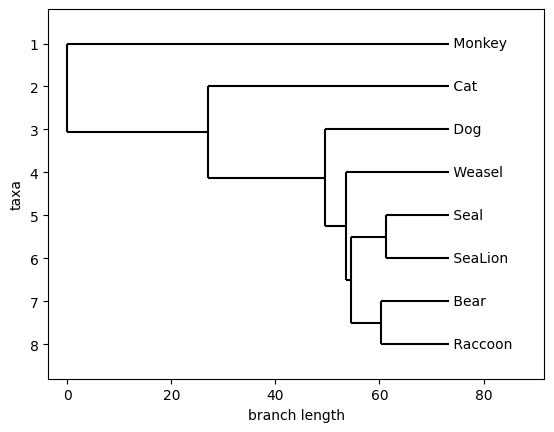

In [28]:
tree = Phylo.read(StringIO(nw), "newick")
Phylo.draw(tree)

In [29]:
tree

Tree(rooted=False, weight=1.0)